# data

In [75]:
import tushare as ts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

token = 'aa6d7dba75bcd6eccd5bbda27e0cf6cf56c4759ec767990bdb041575'
ts.set_token(token)
pro = ts.pro_api()

start_date='20160101'
end_date='20230501'

index_daily = pro.index_daily(ts_code='000001.SH', start_date=start_date, end_date=end_date)
index_daily.trade_date = pd.DatetimeIndex(index_daily.trade_date)
index_daily.set_index("trade_date",inplace=True)
index_daily.sort_index(inplace=True)
index_train = index_daily["2001":"2010"]
index_test = index_daily["2011":"2023"]

In [76]:
index_train

,ts_code,close,open,high,low,pre_close,change,pct_chg,vol,amount
trade_date,,,,,,,,,,


# SMA (SMA (Simple Moving Average) )

In [67]:
def SMA_data(data,SMA1,SMA2,trade_cost=0):
    stockDF = data.copy()
    stockDF["SMA1"] = stockDF.close.rolling(window=SMA1).mean()
    stockDF["SMA2"] = stockDF.close.rolling(window=SMA2).mean()
    stockDF["SMA1_shift1"] = stockDF['SMA1'].shift(1)
    stockDF["SMA2_shift1"] = stockDF['SMA2'].shift(1)
    stockDF.dropna(inplace=True)
    
    # 信号生成与仓位构建
    stockDF.loc[(stockDF['SMA1'] > stockDF['SMA2'] ) &(stockDF['SMA2_shift1'] > stockDF['SMA1_shift1']), 'signal'] = 1
    stockDF.loc[(stockDF['SMA1'] < stockDF['SMA2'] ) &(stockDF['SMA2_shift1'] < stockDF['SMA1_shift1']), 'signal'] = -1
    
    stockDF['position']=stockDF['signal'].shift(1)
    stockDF['position'].fillna(method='ffill',inplace=True)
    stockDF['position'].fillna(0,inplace=True)
    stockDF['position'] = stockDF['position'].replace(-1, 0) # we do not use short 

    
    # 收益率计算
    stockDF["return"] = stockDF["close"].apply(np.log).diff()
    stockDF["strategy"] = stockDF["position"] * (stockDF["return"])
    if trade_cost>0:
        stockDF["trade_cost"] = 0
        stockDF.loc[~stockDF.signal.isna(),["trade_cost"]] = trade_cost
        stockDF["strategy_with_tradecost"] = stockDF["strategy"] - stockDF["trade_cost"]

    return stockDF

In [68]:
data = SMA_data(data = index_train,SMA1=35,SMA2=75,trade_cost=0.003)

ValueError: cannot set a frame with no defined index and a scalar

In [48]:
data.position.unique()

array([0., 1.])

<AxesSubplot:xlabel='trade_date'>

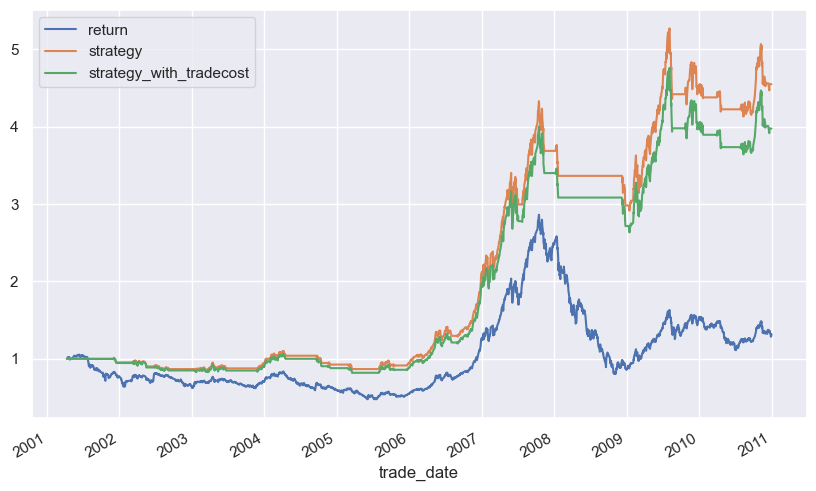

In [49]:
data[["return","strategy","strategy_with_tradecost"]].cumsum().apply(np.exp).plot(figsize=(10,6))

# more evaluation metrics

In [50]:
# 定义函数：计算最大回撤
def max_drawdown(capital):
    """
    该函数计算最大回撤：财富的最大损失幅度
    capital：表示财富值，如果你已经计算出对数收益率为T，可以T.cumsum().apply(np.exp)计算累计财富值
    """
    max_capital = np.zeros(len(capital))
    drawdown = np.zeros(len(capital))
    max_drawdown = 0.0
    
    for i in range(1, len(capital)):
        max_capital[i] = max(max_capital[i-1], capital[i])
        drawdown[i] = (max_capital[i] - capital[i]) / max_capital[i]
        max_drawdown = max(max_drawdown, drawdown[i])
        
    return max_drawdown

# 设置函数：计算净值曲线的绩效指标
def get_Performance_analysis(T,year_day = 252):
    '''
    输入：T表示每日的收益率序列，每年的期数,我们默认是250个交易日
    
    输出：绩效指标
    '''

    # 计算算术年化收益率
    year_ret_mean = np.exp(T.dropna().mean() * year_day) - 1
    year_ret_mean = round(year_ret_mean*100,2)
    
    
    # 计算年化波动率
    volitiy = T.dropna().std()*np.sqrt(year_day)
    volitiy = round(volitiy*100,2)
    
    #计算夏普，无风险收益率记2%
    Sharpe = (year_ret_mean - 2)/volitiy
    Sharpe = round(Sharpe,2)

    # 计算最大回撤
    drawdown = max_drawdown(T.cumsum().apply(np.exp))
    drawdown = round(drawdown*100,2)
    
    # 输出
    return [year_ret_mean,drawdown,Sharpe,volitiy]

In [51]:
sharpe_ratio = get_Performance_analysis(data.strategy_with_tradecost)[0]
sharpe_ratio

15.9

# explore different parameters

In [52]:
from itertools import product
for s1,s2 in product([2,4],[1,3,5]):
    if s1<s2:
        print(s1,s2)

2 3
2 5
4 5


In [53]:
sma1 = range(5,100,5)
sma2 = range(5,200,10)
results = pd.DataFrame()

for SMA1, SMA2 in product(sma1,sma2):
    if SMA1>=SMA2:
        continue
    # 计算不同参数的收益
    index = index_train.copy()
    r = SMA_data(data = index, SMA1=SMA1,SMA2=SMA2,trade_cost=0.002)
    perf_return = get_Performance_analysis(r["return"])[2]
    perf_strategy = get_Performance_analysis(r["strategy"])[2]
    perf_strategy_with_tradecost = get_Performance_analysis(r["strategy_with_tradecost"])[2]
    new_sam = pd.DataFrame({"SMA1":SMA1,
                            "SMA2":SMA2,
                            "Market":perf_return,
                            "Strategy":perf_strategy,
                            "Strategy_with_trade_cost":perf_strategy_with_tradecost,
                            "Strategy_Out":perf_strategy - perf_return,
                            "Strategy_with_tradecost_Out":perf_strategy_with_tradecost - perf_return},
                           index = [0])
    
    # 将新计算结果append到results中    
    results = pd.concat([results, new_sam], ignore_index=True)


In [54]:
results

,SMA1,SMA2,Market,Strategy,Strategy_with_trade_cost,Strategy_Out,Strategy_with_tradecost_Out
0,5,15,0.06,0.47,0.26,0.41,0.20
1,5,25,0.07,0.40,0.26,0.33,0.19
2,5,35,0.06,0.68,0.57,0.62,0.51
3,5,45,0.05,0.82,0.74,0.77,0.69
4,5,55,0.04,0.93,0.86,0.89,0.82
...,...,...,...,...,...,...,...
275,95,155,0.10,0.51,0.49,0.41,0.39
276,95,165,0.10,0.41,0.39,0.31,0.29
277,95,175,0.11,0.34,0.32,0.23,0.21
278,95,185,0.15,0.44,0.42,0.29,0.27


In [57]:
results.sort_values("Strategy_with_tradecost_Out",ascending=False)

,SMA1,SMA2,Market,Strategy,Strategy_with_trade_cost,Strategy_Out,Strategy_with_tradecost_Out
111,35,75,0.04,1.00,0.96,0.96,0.92
186,60,85,0.02,0.96,0.93,0.94,0.91
96,30,85,0.02,0.94,0.92,0.92,0.90
173,55,95,0.02,0.94,0.92,0.92,0.90
145,45,105,0.03,0.94,0.91,0.91,0.88
...,...,...,...,...,...,...,...
92,30,45,0.05,0.31,0.25,0.26,0.20
1,5,25,0.07,0.40,0.26,0.33,0.19
279,95,195,0.14,0.35,0.33,0.21,0.19
74,25,35,0.06,0.22,0.13,0.16,0.07


In [58]:
(results.Strategy_Out>0).value_counts()

True    280
Name: Strategy_Out, dtype: int64

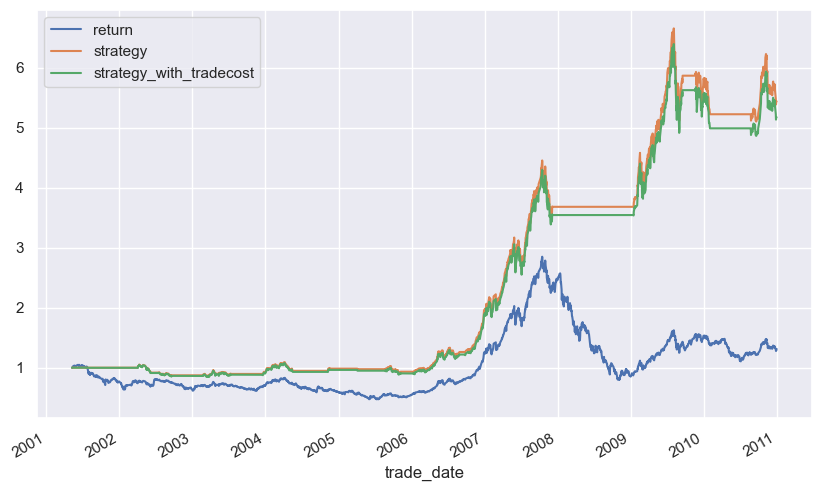

In [59]:
data = SMA_data(data = index_train, SMA1=35,SMA2=75,trade_cost=0.002)

ax = data[["return","strategy","strategy_with_tradecost"]].cumsum().apply(np.exp).plot(figsize=(10,6))

## explore parameters with heatmap

In [60]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

pandas.pivot

> https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.pivot.html

pandas.DataFrame.pivot_table
> https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.pivot_table.html#pandas.DataFrame.pivot_table

In [61]:
data = results.pivot(index="SMA1",columns="SMA2",values="Strategy_Out")

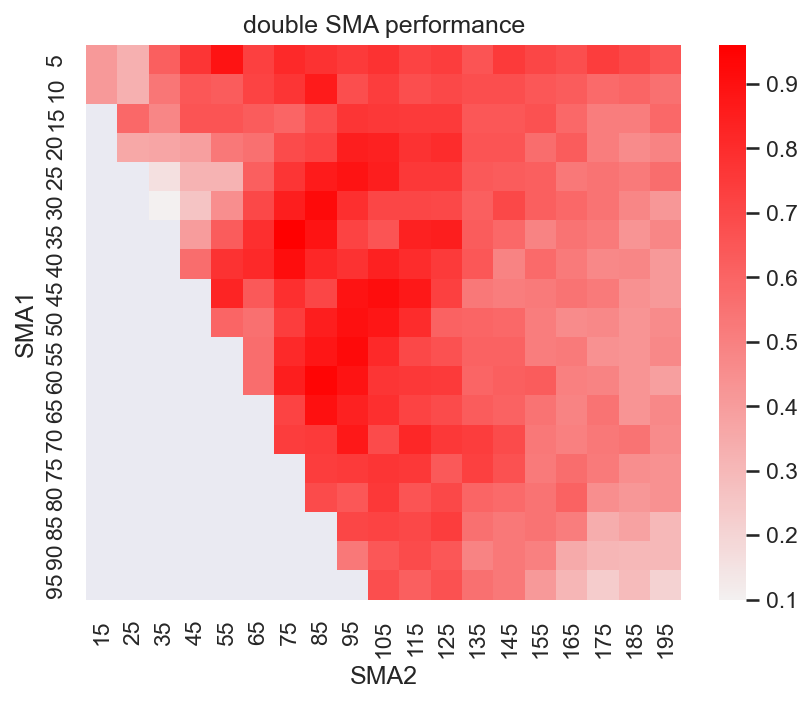

In [62]:
data = results.pivot(index="SMA1",columns="SMA2",values="Strategy_Out")
sns.set()
plt.figure(dpi = 150)
sns.heatmap(data,cmap=sns.light_palette("red",as_cmap=True,reverse=False))
plt.title("double SMA performance")
plt.show()

# test your strategy

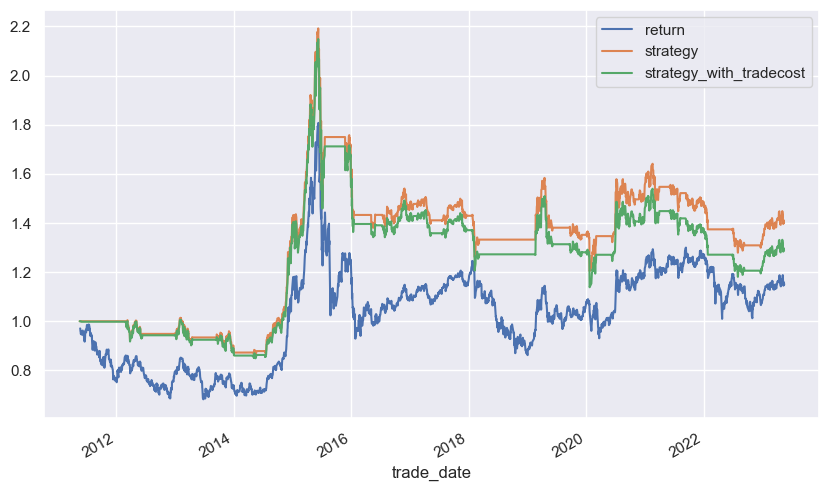

In [250]:
data = SMA_data(data = index_test, SMA1=30,SMA2=90,trade_cost=0.002)
ax = data[["return","strategy","strategy_with_tradecost"]].cumsum().apply(np.exp).plot(figsize=(10,6))

根据不同的评价指标来选择参数有和差异
- return
- sharpe ratio
- volitiy